# Philippine Fuel Prices: Initial Insights (Milestone 4)

**Problem statement:** How have Philippine retail fuel prices (gasoline, diesel, kerosene) changed over time, and how do they vary by region and fuel type?

**Audience:** consumers, journalists and researchers, plus technical reviewers.

**Data:** 48 weekly DOE "NCR Price Monitoring" bulletins (Jul 8, 2025 to Aug 4, 2026), parsed from PDF into `data/processed/ncr_fuel_prices.csv` (one row per week, city, fuel, brand). The data covers Metro Manila (NCR) only, so "region" in this notebook means **NCR city**.

### Key findings at a glance
1. **Time dominates everything.** Prices were nearly flat for eight months, then jumped in March 2026. Diesel went from about ₱58 per liter (Mar 3 bulletin) to a peak of ₱148 (Apr 7) and stood at ₱91 on Aug 4, 2026.
2. **Fuel type matters.** At the peak, diesel was 162% above its pre-shock level; the gasoline grades were 59-71% above theirs.
3. **City matters little; brand matters more.** Cities sit within about -3% to +2.5% of the NCR average, while brands range from about -6% (Flying V) to +6% (Shell). Shell vs independent stations is about ₱7 per liter.

**How to read this notebook:** setup and data notes, summary statistics, five charts (each with an Observation, Implication and Possible Action), one cautious inference check, and an overall takeaway. Every chart is also saved to `output/figures/`.

## 1. Setup and data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

# Works whether the notebook is run from notebooks/ or from the repo root
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_FILE = ROOT / "data" / "processed" / "ncr_fuel_prices.csv"
FIG_DIR = ROOT / "output" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
rng = np.random.default_rng(42)  # fixed seed so bootstrap results are reproducible

def fmt_date(d):
    """Jul 8, 2025 (no leading zero)"""
    return f"{d:%b} {d.day}, {d.year}"

In [2]:
raw = pd.read_csv(DATA_FILE, parse_dates=["week_start"])

# Tidy labels (the DOE source has a "Taguig Cty" typo and shouts brand names)
raw["city"] = raw["city"].replace({"Taguig Cty": "Taguig City"})
raw["brand"] = raw["brand"].replace({
    "CALTEX": "Caltex", "FLYING": "Flying V", "INDEPENDENT": "Independent",
    "PETRON": "Petron", "PHOENIX": "Phoenix", "PTT": "PTT", "SEAOIL": "Seaoil",
    "SHELL": "Shell", "TOTAL": "Total", "UNIOIL": "Unioil",
})
raw["product"] = raw["product"].replace({
    "DIESEL": "Diesel", "DIESEL PLUS": "Diesel Plus", "KEROSENE": "Kerosene",
})

# Only rows where the brand actually reported a price; midpoint of its reported range
reported = raw[raw["status"] == "reported"].copy()
reported["price"] = (reported["price_low"] + reported["price_high"]) / 2

print(f"{len(raw):,} rows loaded; {len(reported):,} reported prices used "
      f"({(raw['status'] == 'no_report').sum()} 'no_report' rows excluded)")
print(f"{raw['week_start'].nunique()} weekly bulletins, "
      f"{raw['week_start'].min():%d %b %Y} to {raw['week_start'].max():%d %b %Y}")
print(f"{raw['city'].nunique()} cities, {raw['brand'].nunique()} brands, "
      f"{raw['product'].nunique()} fuel types")

13,197 rows loaded; 12,940 reported prices used (257 'no_report' rows excluded)
48 weekly bulletins, 08 Jul 2025 to 04 Aug 2026
12 cities, 10 brands, 7 fuel types


### Data notes and choices (read these before the charts)
- **Price used:** the midpoint of each brand's reported low-high range for a city, fuel and week. Ranges are narrow (about ₱2.55 wide on average), so the midpoint is a fair summary, but it is not an individual pump price.
- **Rows used:** only `reported` rows. The 257 `no_report` rows (a brand has an outlet but did not submit a price that week) are excluded.
- **Missing bulletins:** 9 weekly slots between the first and last bulletin have no bulletin (the setup cell below lists them), so charts skip those weeks. The missing **March 10, 2026** bulletin matters: it hides the first step of the price jump.
- **Cities:** 9 cities appear in every period. Marikina, Navotas and Valenzuela only appear from the Mar 17, 2026 bulletin. Trend charts use the 9 long-running cities so the average is not distorted by cities joining; the city comparison handles the new cities separately.
- **NCR average:** brand midpoints are averaged into a city price first, then city prices are averaged, so a city with more reporting brands does not get more weight.
- **Pre-shock vs shock:** "shock period" means bulletins from Mar 17, 2026 onward. The "baseline" is the average of the 8 bulletins just before (Jan 13 to Mar 3, 2026).
- **Outside context (not from this dataset):** news coverage at the time tied the March 2026 surge to the Middle East conflict and reported a national energy emergency ([BusinessWorld, Mar 17](https://wealthinsights.metrobank.com.ph/news/doe-diesel-may-hit-p115-per-liter), [BusinessWorld, Mar 31](https://wealthinsights.metrobank.com.ph/news/doe-says-900000-barrels-of-diesel-to-arrive-next-month)). This dataset can show how big and how fast prices moved, but it cannot show why.

In [3]:
# --- Analysis building blocks -------------------------------------------------
# DOE added three cities (Marikina, Navotas, Valenzuela) in March 2026. To keep the
# time trend honest, the trend charts use only the cities present from the first bulletin.
first_seen = reported.groupby("city")["week_start"].min()
CORE_CITIES = first_seen[first_seen == first_seen.min()].index.tolist()
ALL_CITIES_START = first_seen.max()  # first bulletin in which all 12 cities appear

# The March 10, 2026 bulletin is missing; the first bulletin of the price shock is Mar 17.
SHOCK_START = pd.Timestamp("2026-03-10")

# Two-step average: brand midpoints -> city price -> NCR price (so a city with more
# reporting brands does not get more weight).
city_week = (reported.groupby(["week_start", "city", "product"], as_index=False)["price"].mean())
ncr = (city_week[city_week["city"].isin(CORE_CITIES)]
       .groupby(["week_start", "product"])["price"].mean().unstack())

pre = ncr[ncr.index < SHOCK_START]
shock = ncr[ncr.index >= SHOCK_START]
baseline = pre.tail(8).mean()   # the 8 bulletins just before the shock (Jan 13 - Mar 3, 2026)

all_weeks = pd.Series(sorted(reported["week_start"].unique()))
expected = pd.date_range(all_weeks.min(), all_weeks.max(), freq="7D")
missing_weeks = [d for d in expected if d not in set(all_weeks)]
print(f"Missing weekly bulletins inside the date range: {len(missing_weeks)} -> "
      + ", ".join(f"{d:%b} {d.day}, {d.year}" for d in missing_weeks))
print("Core cities (9):", ", ".join(CORE_CITIES))
print(f"Pre-shock bulletins: {len(pre)} | shock-period bulletins: {len(shock)}")

Missing weekly bulletins inside the date range: 9 -> Aug 26, 2025, Sep 2, 2025, Sep 23, 2025, Oct 21, 2025, Nov 4, 2025, Nov 11, 2025, Mar 10, 2026, Jun 2, 2026, Jun 30, 2026
Core cities (9): Caloocan City, Makati City, Manila City, Muntinlupa City, Parañaque City, Pasay City, Pasig City, Quezon City, Taguig City
Pre-shock bulletins: 29 | shock-period bulletins: 19


## 2. Summary statistics

Before charting, a look at the shape of the data: the NCR average price for each fuel, split into the months before and after the March 2026 shock.

In [4]:
stats = pd.DataFrame({
    "Pre-shock mean": pre.mean(),
    "Pre-shock min": pre.min(),
    "Pre-shock max": pre.max(),
    "Shock-period mean": shock.mean(),
    "Shock-period min": shock.min(),
    "Shock-period max": shock.max(),
    "Overall mean": ncr.mean(),
    "Overall median": ncr.median(),
    "Overall std dev": ncr.std(),
}).loc[["Diesel", "Diesel Plus", "Kerosene", "RON 91", "RON 95", "RON 97", "RON 100"]]
stats.round(1)

,Pre-shock mean,Pre-shock min,Pre-shock max,Shock-period mean,Shock-period min,Shock-period max,Overall mean,Overall median,Overall std dev
product,,,,,,,,,
Diesel,56.6,54.5,60.2,94.5,69.2,148.2,71.6,57.3,23.1
Diesel Plus,63.5,61.2,67.3,100.6,73.7,156.5,78.2,64.6,23.3
Kerosene,79.4,74.4,87.2,129.0,103.6,163.9,99.0,83.3,27.2
RON 91,56.9,55.9,59.0,83.5,74.7,96.0,67.4,57.9,13.7
RON 95,60.2,58.9,62.2,86.8,77.6,100.1,70.7,61.2,13.8
RON 97,65.8,64.1,67.6,92.4,83.2,104.0,76.4,66.9,13.7
RON 100,67.0,65.5,69.2,92.8,84.0,106.3,77.2,68.4,13.4


**What the statistics say**
- **Before the shock, prices were very stable.** Across 29 bulletins, diesel stayed between ₱54.5 and ₱60.2 and RON 95 between ₱58.9 and ₱62.2. Gasoline and diesel started close together (about ₱56-60), while kerosene was already higher (about ₱79).
- **The overall mean is misleading.** For every fuel the mean is well above the median (diesel: ₱71.6 mean vs ₱57.3 median). The 19 shock-period bulletins drag the mean up, so the "average price over the whole year" describes neither the calm months nor the shock months. Later sections always say which period they mean.
- **Diesel and kerosene are the most variable.** Their standard deviation is ₱23-27, about double that of the gasoline grades (about ₱13-14). During the shock, diesel alone ranged from ₱69.2 to ₱148.2 across bulletins.

Why this matters: it justifies splitting the analysis into a calm period and a shock period, and describing changes as percentages above a baseline.

## 3. Charts

### Chart 1 - How have fuel prices changed over time?

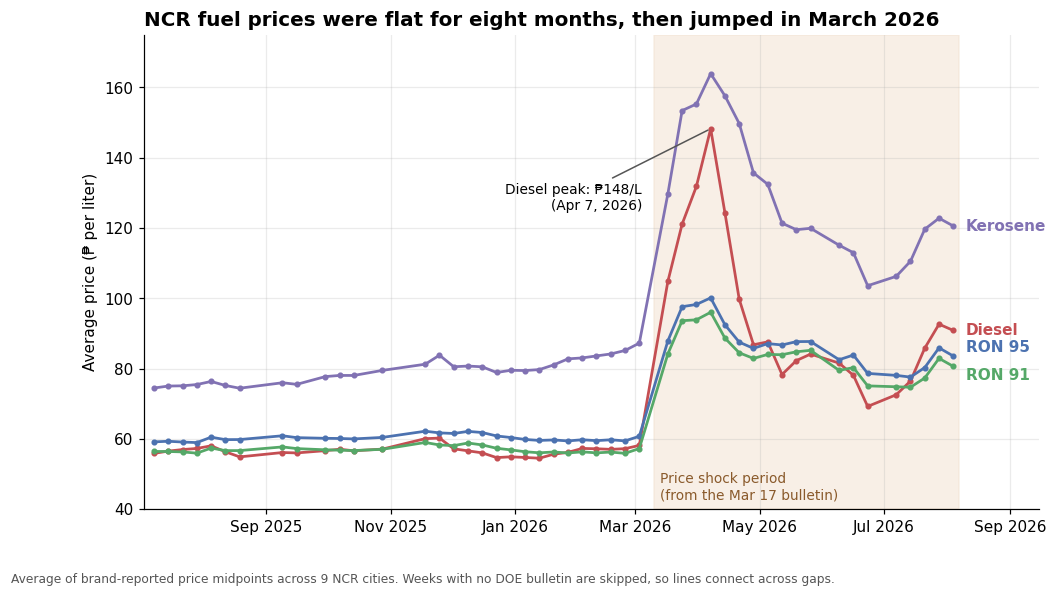

In [5]:
main = ["Diesel", "Kerosene", "RON 95", "RON 91"]
colors = {"Diesel": "#c44e52", "Kerosene": "#8172b3", "RON 95": "#4c72b0", "RON 91": "#55a868"}

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.axvspan(SHOCK_START, ncr.index.max() + pd.Timedelta(days=3), color="#f3e3d3", alpha=0.55, zorder=0)
ax.text(SHOCK_START + pd.Timedelta(days=3), 42, "Price shock period\n(from the Mar 17 bulletin)",
        fontsize=9, va="bottom", color="#8a5a2b")

label_nudge = {"RON 95": 6, "RON 91": -6}  # keep the two gasoline labels from overlapping
for p in main:
    ax.plot(ncr.index, ncr[p], marker="o", ms=3, lw=1.8, color=colors[p])
    ax.annotate(p, (ncr.index[-1], ncr[p].iloc[-1]), xytext=(8, label_nudge.get(p, 0)), textcoords="offset points",
                va="center", color=colors[p], fontsize=10, fontweight="bold")

peak_date = ncr["Diesel"].idxmax()
ax.annotate(f"Diesel peak: ₱{ncr['Diesel'].max():.0f}/L\n({fmt_date(peak_date)})",
            xy=(peak_date, ncr["Diesel"].max()), xytext=(-45, -45), textcoords="offset points",
            ha="right", va="center", fontsize=9, arrowprops=dict(arrowstyle="-", color="#555"))

ax.set_ylim(40, 175)
ax.set_xlim(ncr.index.min() - pd.Timedelta(days=5), ncr.index.max() + pd.Timedelta(days=42))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylabel("Average price (₱ per liter)")
ax.set_title("NCR fuel prices were flat for eight months, then jumped in March 2026")
fig.text(0.01, -0.01, "Average of brand-reported price midpoints across 9 NCR cities. Weeks with no DOE "
         "bulletin are skipped, so lines connect across gaps.", fontsize=8, color="#555")
fig.savefig(FIG_DIR / "01_price_trend_by_fuel.png", dpi=150, bbox_inches="tight")
plt.show()

### Observation
From July 2025 to early March 2026 prices barely moved: diesel stayed within ₱54.5-60.2 and RON 95 within ₱58.9-62.2. Diesel then jumped from ₱58.1 (Mar 3 bulletin) to ₱104.8 (Mar 17 bulletin) and peaked at ₱148.2 on Apr 7, 2026. It fell to ₱69.2 by Jun 23 (briefly below RON 91 and RON 95) before rebounding to ₱90.8 on Aug 4.

### Implication
For the project question, the biggest answer is *when*, not *where*: the swing in diesel (about ₱55 to ₱148) is far larger than any difference between cities or brands. The missing Mar 10 bulletin also means the dataset cannot show how quickly the first jump happened, only that it was complete by Mar 17.

### Possible Action
Consumers and journalists should compare today's prices with the pre-shock baseline (about ₱57 for diesel and ₱60 for RON 95), not with a full-year average. Researchers who want to explain the rise need outside series such as crude prices or exchange rates; this dataset can describe the move but not its cause.

### Chart 2 - Which fuel type was hit hardest?

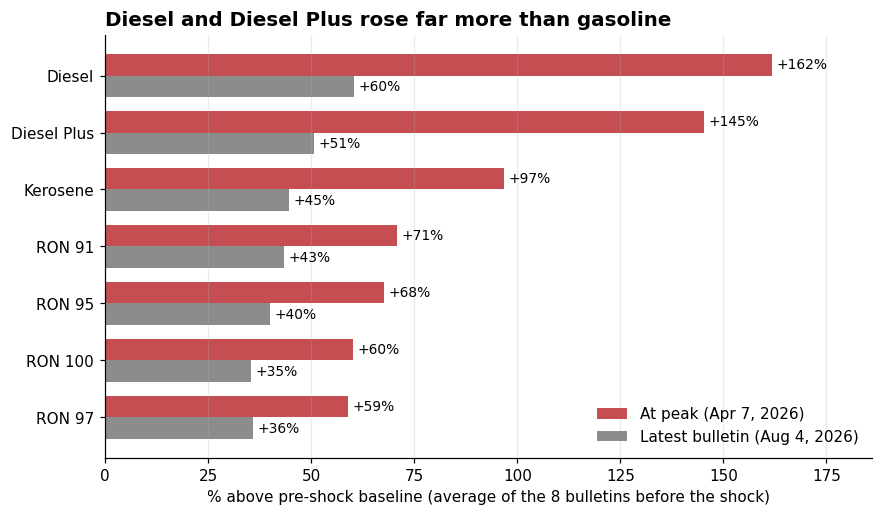

,baseline,peak,latest,peak_pct,latest_pct
product,,,,,
RON 97,65.5,104.0,89.1,58.9,36.0
RON 100,66.4,106.3,89.9,60.2,35.4
RON 95,59.7,100.1,83.6,67.7,39.9
RON 91,56.2,96.0,80.6,70.8,43.4
Kerosene,83.3,163.9,120.6,96.7,44.7
Diesel Plus,63.8,156.5,96.2,145.3,50.8
Diesel,56.6,148.2,90.8,161.8,60.4


In [6]:
hit = pd.DataFrame({"baseline": baseline, "peak": ncr.max(), "latest": ncr.iloc[-1]})
hit["peak_pct"] = (hit["peak"] / hit["baseline"] - 1) * 100
hit["latest_pct"] = (hit["latest"] / hit["baseline"] - 1) * 100
hit = hit.sort_values("peak_pct")
peak_dates = ncr.idxmax()
assert peak_dates.nunique() == 1, "fuels peaked on different dates; update the chart labels"
PEAK_LABEL = f"At peak ({fmt_date(peak_dates.iloc[0])})"

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(hit)); h = 0.38
b1 = ax.barh(y + h / 2, hit["peak_pct"], h, color="#c44e52", label=PEAK_LABEL)
b2 = ax.barh(y - h / 2, hit["latest_pct"], h, color="#8c8c8c", label=f"Latest bulletin ({fmt_date(ncr.index[-1])})")
for bars in (b1, b2):
    ax.bar_label(bars, fmt="+%.0f%%", padding=3, fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(hit.index)
ax.set_xlim(0, hit["peak_pct"].max() * 1.15)
ax.set_xlabel("% above pre-shock baseline (average of the 8 bulletins before the shock)")
ax.set_title("Diesel and Diesel Plus rose far more than gasoline")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.savefig(FIG_DIR / "02_increase_by_fuel.png", dpi=150, bbox_inches="tight")
plt.show()
hit.round(1)

### Observation
At the Apr 7 peak, diesel was 162% above its pre-shock baseline and Diesel Plus 145%, versus 59-71% for the gasoline grades (RON 91 +71%, RON 95 +68%) and +97% for kerosene. By Aug 4 every fuel had eased but stayed above baseline: diesel +60%, RON 91 +43%, RON 95 +40%.

### Implication
The shock was not even: the fuels commonly used by jeepneys, trucks and household kerosene stoves rose the most, so commuters and small businesses were probably squeezed harder than private gasoline users. This dataset only measures the pump prices, not that downstream impact.

### Possible Action
Journalists should always name the fuel when quoting an increase: "prices doubled" is true for diesel at the peak (+162%) but overstates gasoline (+68%). Consumers can use the latest-bulletin bars to see which fuel is still furthest above its old price (diesel, +60%).

### Chart 3 - How volatile were weekly price changes?

The project's secondary KPI is week-over-week % change. Because DOE did not publish every week, some "previous bulletins" are 2-3 weeks back; those bars are coloured differently so they are not mistaken for one-week moves.

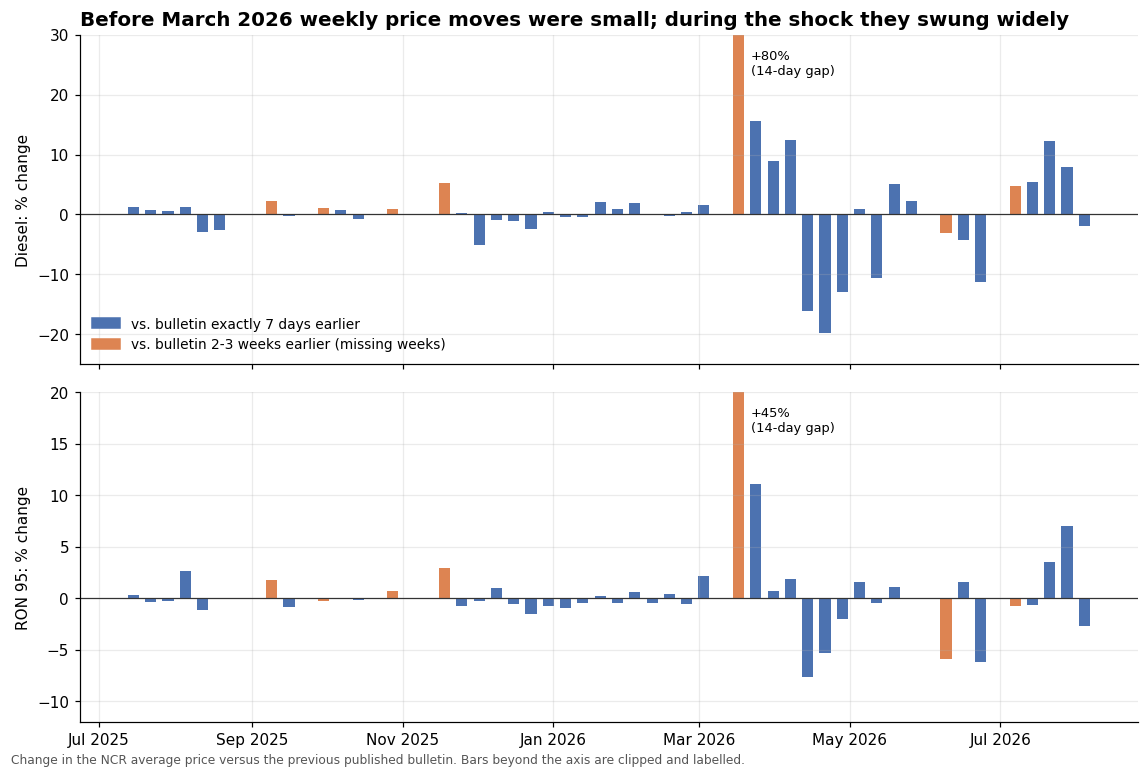

,"Pre-shock (std dev, pct pts)","Shock period (std dev, pct pts)",Largest 7-day rise (%),Largest 7-day fall (%)
product,,,,
Diesel,1.7,11.0,15.6,-19.8
RON 95,1.0,4.7,11.1,-7.7


In [7]:
gap_days = ncr.index.to_series().diff().dt.days
chg = ncr[["Diesel", "RON 95"]].pct_change() * 100
clip = {"Diesel": (-25, 30), "RON 95": (-12, 20)}

fig, axes = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True)
for ax, p in zip(axes, ["Diesel", "RON 95"]):
    lo, hi = clip[p]
    cols = np.where(gap_days == 7, "#4c72b0", "#dd8452")
    ax.bar(chg.index, chg[p].clip(lo, hi), width=4.5, color=cols)
    ax.axhline(0, color="#333", lw=0.8)
    for d, v in chg[p].items():
        if pd.notna(v) and (v > hi or v < lo):
            ax.annotate(f"{v:+.0f}%\n({int(gap_days[d])}-day gap)", (d, hi if v > 0 else lo),
                        xytext=(8, -26 if v > 0 else 4), textcoords="offset points", fontsize=8.5)
    ax.set_ylim(lo, hi)
    ax.set_ylabel(f"{p}: % change")
axes[0].set_title("Before March 2026 weekly price moves were small; during the shock they swung widely")
axes[0].legend(handles=[Patch(color="#4c72b0", label="vs. bulletin exactly 7 days earlier"),
                        Patch(color="#dd8452", label="vs. bulletin 2-3 weeks earlier (missing weeks)")],
               loc="lower left", frameon=False, fontsize=9)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.text(0.01, 0.0, "Change in the NCR average price versus the previous published bulletin. Bars beyond the axis are clipped and labelled.",
         fontsize=8, color="#555")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_weekly_change.png", dpi=150, bbox_inches="tight")
plt.show()

# Volatility for like-for-like 7-day changes only
seven = (gap_days == 7)
vol = pd.DataFrame({
    "Pre-shock (std dev, pct pts)": chg[seven & (chg.index < SHOCK_START)].std(),
    "Shock period (std dev, pct pts)": chg[seven & (chg.index >= SHOCK_START)].std(),
    "Largest 7-day rise (%)": chg[seven].max(),
    "Largest 7-day fall (%)": chg[seven].min(),
}).round(1)
vol

### Observation
Before the shock, bulletin-to-bulletin changes were tiny: the typical swing (standard deviation, using only exact 7-day gaps) was 1.7 percentage points for diesel and 1.0 for RON 95. During the shock it rose to 11.0 and 4.7. The biggest 7-day moves were +15.6% (diesel, Mar 24) and -19.8% (diesel, Apr 21). The tall +80% and +45% bars on Mar 17 are not one-week moves: they span 14 days because the Mar 10 bulletin is missing.

### Implication
Volatility changed, not just the level. In 2025 buying a week earlier or later made almost no difference; in spring 2026 a week could mean a double-digit swing in either direction, and the fall was as sharp as the rise.

### Possible Action
Consumers and small fleet operators should check the weekly DOE bulletin during volatile periods instead of assuming last week's price still holds. For the project's dashboard, show "change vs previous bulletin" together with the gap length, so multi-week jumps are not mistaken for weekly ones.

### Chart 4 - Do some NCR cities charge more than others?

Raw city averages would be misleading: Marikina, Navotas and Valenzuela only appear from March 2026, when prices were already far higher. So every city is compared with the **NCR average for the same fuel in the same week**, using only bulletins where all 12 cities appear.

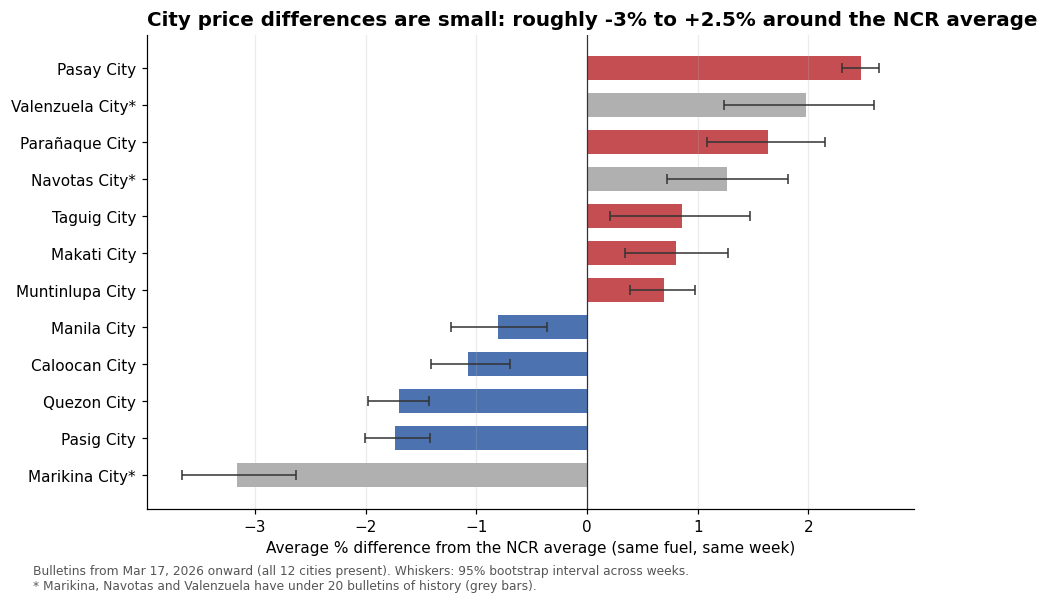

Spearman rank correlation on the 9 core cities: 0.75


,"Mar-Aug 2026, 12 cities","Jul 2025-Aug 2026, 9 core cities"
city,,
Marikina City,-3.16,NaN
Pasig City,-1.74,-1.40
Quezon City,-1.70,-2.22
Caloocan City,-1.08,-1.65
Manila City,-0.80,-1.52
Muntinlupa City,0.69,0.95
Makati City,0.81,0.86
Taguig City,0.86,0.91
Navotas City,1.27,NaN


In [8]:
def city_premium(cw):
    """Each city's % difference from the same-week, same-fuel average of the cities present."""
    cw = cw.copy()
    cw["market"] = cw.groupby(["week_start", "product"])["price"].transform("mean")
    cw["premium"] = (cw["price"] / cw["market"] - 1) * 100
    return cw

def week_bootstrap_ci(series_by_week, n=5000):
    """95% CI of a mean, resampling whole weeks (all cities/brands in a week move together)."""
    vals = series_by_week.dropna().to_numpy()
    means = [rng.choice(vals, len(vals)).mean() for _ in range(n)]
    return np.percentile(means, [2.5, 97.5])

cp = city_premium(city_week[city_week["week_start"] >= ALL_CITIES_START])
by_week = cp.groupby(["city", "week_start"])["premium"].mean().unstack(0)
city_tbl = pd.DataFrame({"mean": by_week.mean()})
city_tbl[["lo", "hi"]] = [week_bootstrap_ci(by_week[c]) for c in city_tbl.index]
city_tbl = city_tbl.sort_values("mean")
NEW_CITIES = ["Marikina City", "Navotas City", "Valenzuela City"]

fig, ax = plt.subplots(figsize=(9, 5.6))
y = np.arange(len(city_tbl))
cols = ["#b0b0b0" if c in NEW_CITIES else ("#c44e52" if m > 0 else "#4c72b0")
        for c, m in zip(city_tbl.index, city_tbl["mean"])]
ax.barh(y, city_tbl["mean"], color=cols, height=0.65)
ax.errorbar(city_tbl["mean"], y, xerr=[city_tbl["mean"] - city_tbl["lo"], city_tbl["hi"] - city_tbl["mean"]],
            fmt="none", ecolor="#333", elinewidth=1, capsize=3)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{c}*" if c in NEW_CITIES else c for c in city_tbl.index])
ax.set_xlabel("Average % difference from the NCR average (same fuel, same week)")
ax.set_title("City price differences are small: roughly -3% to +2.5% around the NCR average")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, f"Bulletins from {fmt_date(ALL_CITIES_START)} onward (all 12 cities present). Whiskers: 95% bootstrap interval across weeks.\n"
         "* Marikina, Navotas and Valenzuela have under 20 bulletins of history (grey bars).", fontsize=8, color="#555")
fig.savefig(FIG_DIR / "04_city_vs_ncr_average.png", dpi=150, bbox_inches="tight")
plt.show()

# Robustness check: does the ranking hold on the longer, 9-city history?
long_cp = city_premium(city_week[city_week["city"].isin(CORE_CITIES)])
robust = pd.DataFrame({
    "Mar-Aug 2026, 12 cities": city_tbl["mean"],
    "Jul 2025-Aug 2026, 9 core cities": long_cp.groupby("city")["premium"].mean(),
}).round(2).sort_values("Mar-Aug 2026, 12 cities")
print("Spearman rank correlation on the 9 core cities:",
      round(robust.dropna().rank().corr(method="pearson").iloc[0, 1], 2))
robust

### Observation
City differences are small: from -3.2% (Marikina) to +2.5% (Pasay) relative to the NCR average for the same fuel and week. Pasay is highest, while Quezon City, Pasig, Manila and Caloocan sit below average. The same pattern shows up in the longer Jul 2025 to Aug 2026 history of the 9 long-running cities (rank correlation 0.75), so it is not just a feature of the shock months.

### Implication
A gap of 1-3% is roughly ₱1-3 per liter at typical prices, small enough that driving to another city would likely cost more than it saves. Taguig, Makati and Muntinlupa cannot be told apart from each other (overlapping whiskers), and the three newest cities have under 20 bulletins of history, so their positions are tentative.

### Possible Action
Consumers in NCR need not cross city lines to save on fuel; comparing brands (next chart) pays off more. Journalists should avoid "city X has the cheapest fuel" headlines on gaps this small. Researchers who want to explain city differences would need station-level data.

### Chart 5 - Which brands price above or below the market?

Same idea as the city chart: each brand's price is compared with the **average of all brands in the same city, for the same fuel, in the same week** (cells with at least 3 brands), so brands are never penalised for selling in dearer weeks, cities or fuels.

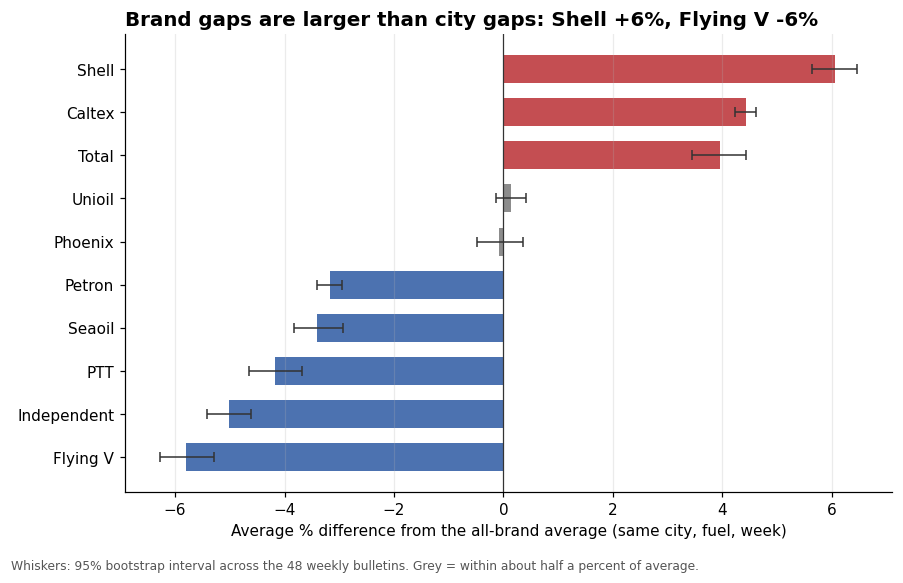

,mean,n_rows,lo,hi
brand,,,,
Flying V,-5.80,1113,-6.28,-5.29
Independent,-5.01,1252,-5.41,-4.60
PTT,-4.17,228,-4.64,-3.69
Seaoil,-3.41,842,-3.82,-2.93
Petron,-3.17,1678,-3.41,-2.95
Phoenix,-0.08,592,-0.48,0.36
Unioil,0.14,1147,-0.13,0.41
Total,3.95,835,3.44,4.43
Caltex,4.43,1549,4.24,4.61


In [9]:
cell_mean = reported.groupby(["week_start", "city", "product"])["price"].transform("mean")
cell_n = reported.groupby(["week_start", "city", "product"])["price"].transform("count")
rb = reported[cell_n >= 3].copy()
rb["premium"] = (rb["price"] / cell_mean[rb.index] - 1) * 100

by_week_b = rb.groupby(["brand", "week_start"])["premium"].mean().unstack(0)
brand_tbl = pd.DataFrame({"mean": by_week_b.mean(), "n_rows": rb.groupby("brand").size()})
brand_tbl[["lo", "hi"]] = [week_bootstrap_ci(by_week_b[b]) for b in brand_tbl.index]
brand_tbl = brand_tbl.sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 5.4))
y = np.arange(len(brand_tbl))
cols = ["#c44e52" if m > 0.5 else ("#4c72b0" if m < -0.5 else "#8c8c8c") for m in brand_tbl["mean"]]
ax.barh(y, brand_tbl["mean"], color=cols, height=0.65)
ax.errorbar(brand_tbl["mean"], y, xerr=[brand_tbl["mean"] - brand_tbl["lo"], brand_tbl["hi"] - brand_tbl["mean"]],
            fmt="none", ecolor="#333", elinewidth=1, capsize=3)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(brand_tbl.index)
ax.set_xlabel("Average % difference from the all-brand average (same city, fuel, week)")
ax.set_title("Brand gaps are larger than city gaps: Shell +6%, Flying V -6%")
ax.grid(axis="y", visible=False)
fig.text(0.01, -0.02, "Whiskers: 95% bootstrap interval across the 48 weekly bulletins. Grey = within about half a percent of average.",
         fontsize=8, color="#555")
fig.savefig(FIG_DIR / "05_brand_vs_market.png", dpi=150, bbox_inches="tight")
plt.show()
brand_tbl.round(2)

### Observation
Compared with the all-brand average in the same city, fuel and week, Shell prices about 6.0% above (95% interval 5.6% to 6.5%), Caltex 4.4% and Total 4.0% above. Flying V (-5.8%), Independent (-5.0%), PTT (-4.2%), Seaoil (-3.4%) and Petron (-3.2%) price below average, while Phoenix and Unioil sit within half a percent of it.

### Implication
Brand gaps (about 12 points from lowest to highest) are roughly twice as wide as city gaps (about 6 points), so in this data *who* you buy from matters more than *where* in NCR you buy. "Big brand means expensive" does not hold across the board: Petron, one of the three most-reported brands here, prices below average.

### Possible Action
Consumers can compare brand prices at the pump in the same week, since the brand choice moves the price by several pesos per liter while the city choice moves it by one to three. Journalists should report brand gaps in both pesos and percent. Researchers should investigate why the gaps exist (fuel formulation, station type, location and service all differ by brand).

## 4. Inference check: do Shell stations price above independent stations?

### Relationship or comparison
I am checking whether **Shell** prices differ from **Independent** (non-branded) stations for the **same fuel, in the same city, in the same week**. Comparing within the same city, fuel and week removes the effect of the calendar, location and fuel mix. I chose this pair because it is the sharpest contrast in Chart 5, which means the gap below is near the *upper end* of what brand-to-brand comparisons would show.

In [10]:
# Shell vs independent stations, same fuel, same city, same week. NOTE: this pair was chosen
# because it is the sharpest contrast in Chart 5, so the gap is near the upper end of what
# brand-vs-brand comparisons show (see the 'What I cannot conclude' list below).
pair = (reported[reported["brand"].isin(["Shell", "Independent"])]
        .pivot_table(index=["week_start", "city", "product"], columns="brand", values="price").dropna())
pair["diff"] = pair["Shell"] - pair["Independent"]
pair["pct"] = (pair["Shell"] / pair["Independent"] - 1) * 100

wk = pair.groupby(level="week_start")[["diff", "pct"]].mean()
lo_d, hi_d = week_bootstrap_ci(wk["diff"])
lo_p, hi_p = week_bootstrap_ci(wk["pct"])

summary = pd.Series({
    "Paired city-week-fuel comparisons": len(pair),
    "Weekly bulletins covered": wk.shape[0],
    "Cities with both Shell and Independent": pair.index.get_level_values("city").nunique(),
    "Average gap, Shell minus Independent (₱/L)": round(wk["diff"].mean(), 2),
    "  95% interval (₱/L)": f"{lo_d:.2f} to {hi_d:.2f}",
    "Average gap (%)": round(wk["pct"].mean(), 1),
    "  95% interval (%)": f"{lo_p:.1f} to {hi_p:.1f}",
    "Share of comparisons where Shell is higher": f"{(pair['diff'] > 0).mean():.1%}",
    "Weeks where Shell is higher on average": f"{(wk['diff'] > 0).mean():.0%}",
})
display(summary.to_frame("Shell vs Independent"))

by_period = pd.DataFrame({
    "Pre-shock": [wk[wk.index < SHOCK_START]["diff"].mean(), wk[wk.index < SHOCK_START]["pct"].mean()],
    "Shock period": [wk[wk.index >= SHOCK_START]["diff"].mean(), wk[wk.index >= SHOCK_START]["pct"].mean()],
}, index=["Gap (₱/L)", "Gap (%)"]).round(1)
display(by_period)

by_fuel = pair.groupby(level="product")["diff"].agg(["mean", "count"]).round(2)
by_fuel.columns = ["Average gap (₱/L)", "Paired comparisons"]
by_fuel.loc[["Diesel", "RON 91", "RON 95", "Diesel Plus", "RON 97"]]

,Shell vs Independent
Paired city-week-fuel comparisons,1252
Weekly bulletins covered,48
Cities with both Shell and Independent,10
"Average gap, Shell minus Independent (₱/L)",7.45
95% interval (₱/L),7.11 to 7.77
Average gap (%),12.1
95% interval (%),11.1 to 13.0
Share of comparisons where Shell is higher,95.7%
Weeks where Shell is higher on average,100%


,Pre-shock,Shock period
Gap (₱/L),7.9,6.8
Gap (%),14.6,8.3


,Average gap (₱/L),Paired comparisons
product,,
Diesel,4.71,405
RON 91,5.35,405
RON 95,11.57,405
Diesel Plus,12.60,25
RON 97,15.15,12


### What the data shows
Across 1,252 paired comparisons in 10 cities, Shell's price was higher than the independent stations' price in 95.7% of cases, and higher on average in **every one of the 48 weekly bulletins**. The average gap is **₱7.45 per liter** (95% interval ₱7.11 to ₱7.77), or **12.1%** (11.1% to 13.0%). The gap in pesos was similar before and during the shock (₱7.9 vs ₱6.8), so the percentage gap narrowed (14.6% to 8.3%) only because overall prices rose. For the three fuels with large samples (405 comparisons each) the gap is ₱4.71 for diesel, ₱5.35 for RON 91 and ₱11.57 for RON 95.

### What I can say carefully
In these DOE bulletins, Shell's reported prices were reliably and consistently higher than independent stations' prices. This held across weeks, cities and fuels, and it was larger for RON 95 than for diesel or RON 91.

### What I cannot conclude
- **That Shell charges more for the same product.** Fuel formulations, additives, station type, location and services can differ, and this data cannot separate them from the brand itself.
- **Why the gap exists.** The data is observational and has no station-level detail, so it supports no causal claim.
- **That "Independent" means one company.** It is a mixed group of unbranded stations and appears in only 10 of the 12 cities.
- **That DOE's sample is representative.** I do not know which outlets DOE monitors each week, and each value is the midpoint of a reported range.
- **That this is a typical brand gap.** I picked the most extreme contrast on purpose; other pairs (for example Caltex vs Seaoil) would show smaller gaps.
- **That the intervals are exact.** They treat each weekly bulletin as an independent sample, but consecutive weeks are related, so the true uncertainty is somewhat wider than shown.
- **Anything about Diesel Plus or RON 97.** Only 25 and 12 paired comparisons exist, so they are left out of the interpretation.

## 5. Overall takeaway

**Answering the problem statement.** Over the past year, NCR fuel prices went through two very different phases: eight calm months, then a sharp 2026 shock that has eased but not reversed. Diesel peaked 162% above its pre-shock level and was still 60% above it on Aug 4, 2026; gasoline grades peaked 59-71% above baseline and were 35-43% above on Aug 4. Across fuels, diesel, Diesel Plus and kerosene were hit hardest. Across places and sellers, differences exist but are small compared with the time effect: cities differ by only a few percent, while brands differ by about twice as much (Shell vs independent stations is about ₱7 per liter).

**Limits to keep in mind.** The data covers NCR cities only (not other regions), 9 weekly bulletins are missing (including the critical Mar 10, 2026 one), prices are range midpoints rather than individual pump prices, and nothing here proves *why* prices moved or differ by brand.

**Next steps.**
- Add regional DOE bulletins (Luzon, Visayas, Mindanao) to answer the "by region" part of the problem statement properly.
- Use the findings in the dashboard: the price trend with the shock period shaded, the "% above baseline" view, and a brand comparison.
- If the cause of the price swings matters, add outside series (crude oil, exchange rate) in a later phase.